<a href="https://colab.research.google.com/github/cbishop4/MSE7530/blob/main/Manual_least_squares_SAXS_F2026_ANSWERS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exam Preparation: SAXS and Least-Squares Fitting

In this notebook you will cover two main concepts:

1. **Small-angle scattering of dilute spheres** — including $R_g$ and the Guinier region
2. **Manual least-squares fitting** — searching a parameter space to match an unknown distribution

For the sections marked **Your Task**, you must write your own code. You may use AI assistance, but you should understand every line before the exam. **You should be able to explain everything in this notebook on the exam.** Answers will be posted on Friday.  

**AI Disclosure**: I prepared this entire notebook with examples by hand; after it was finished, I ran it through Claude to check for errors and clean it up. It added a bit to the markup, revised the numbering/organization, and laid out the "your tasks" a bit more cleanly along with the pencil emoji.

## Setup

Run these two cells first to import libraries and download the course data.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import cm
import pandas as pd
from scipy.stats import linregress

In [2]:
# Download course data repository (only needs to run once per session)
!git clone https://github.com/cbishop4/MSE7530.git

Cloning into 'MSE7530'...
remote: Enumerating objects: 1038, done.
remote: Counting objects: 100% (173/173), done.
remote: Compressing objects: 100% (111/111), done.
remote: Total 1038 (delta 135), reused 62 (delta 62), pack-reused 865 (from 1)
Receiving objects: 100% (1038/1038), 166.58 MiB | 15.51 MiB/s, done.
Resolving deltas: 100% (413/413), done.
Updating files: 100% (360/360), done.


---
# Part 1: Least-Squares Fitting of Scattering from a Bidisperse Sphere Solution

In this exercise you will use the analytical form factor for dilute spheres to fit an unknown bidisperse distribution.

## 1.1 Form factor for a dilute sphere

The squared form factor (equal to the scattered intensity) for a dilute solution of spheres of radius $r$ is:

$$P(Q, r) = \left( \frac{3\,[\sin(Qr) - Qr\cos(Qr)]}{Q^3 r^3} \right)^2$$

The function below evaluates this expression.

In [3]:
def FQ2_sphere(radius, q):
    """Squared form factor for a dilute sphere of given radius at wavevector q."""
    return (3 * (np.sin(q * radius) - q * radius * np.cos(q * radius)) /
            (q**3 * radius**3))**2

## 1.2 Monodisperse scattering

We can visualise the scattering from a single population of 100 nm spheres.
Note the fringe spacing — **it is important that you understand how fringe spacing relates to sphere size.**

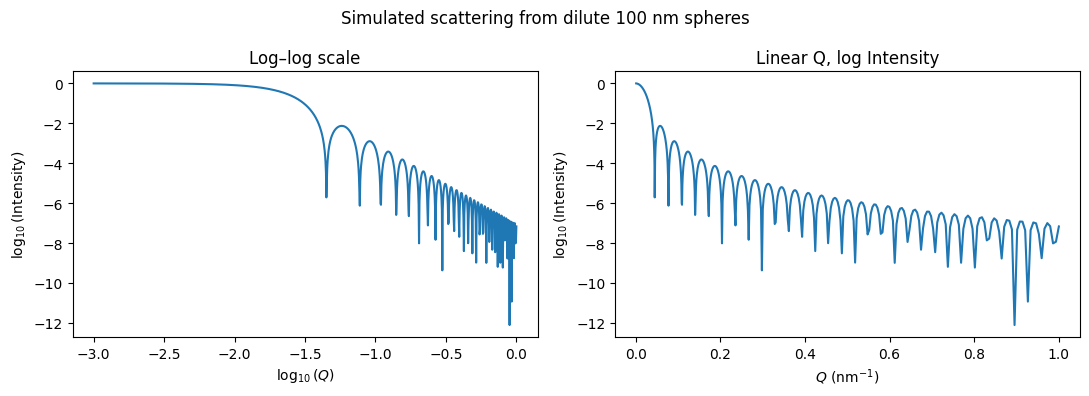

In [4]:
qrange = np.logspace(-3, 0, 1000)  # Q values evenly spaced on a log scale (nm⁻¹)
scatter = FQ2_sphere(100., qrange)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(np.log10(qrange), np.log10(scatter))
axes[0].set_xlabel(r'$\log_{10}(Q)$')
axes[0].set_ylabel(r'$\log_{10}$(Intensity)')
axes[0].set_title('Log–log scale')

axes[1].plot(qrange, np.log10(scatter))
axes[1].set_xlabel(r'$Q\ (\mathrm{nm}^{-1})$')
axes[1].set_ylabel(r'$\log_{10}$(Intensity)')
axes[1].set_title('Linear Q, log Intensity')

fig.suptitle('Simulated scattering from dilute 100 nm spheres')
plt.tight_layout()

## 1.3 Guinier region check

In the Guinier region, for a **sphere** specifically, the intensity approximates to:

$$I(Q) \approx \Delta\rho^2 V_p^2 \, e^{-Q^2 R^2/5}$$

Taking the natural log: $\ln I = \text{const} - \frac{R^2}{5}Q^2$.

A plot of $\ln I$ vs $Q^2$ (a **Guinier plot**) should therefore be linear at low $Q$, with slope $= -R^2/5$.

> **Note:** For an arbitrary particle shape, the exponent is $-R_g^2/3$ (we use this in Part 2).
> For a solid sphere, $R_g^2 = 3R^2/5$, which gives the factor of $1/5$ above.

(0.0, 0.003)

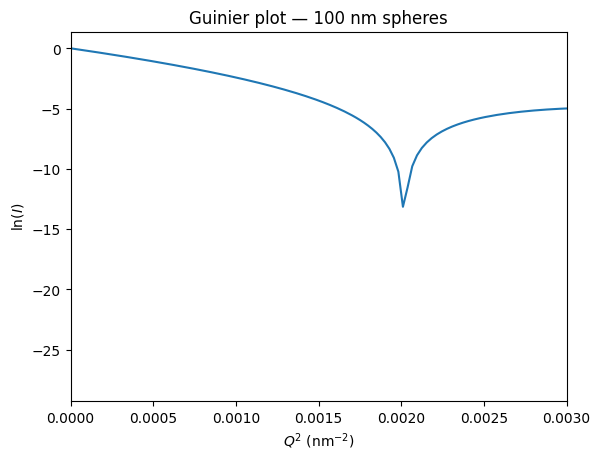

In [5]:
q2  = qrange**2
lnI = np.log(scatter)

fig, ax = plt.subplots()
ax.plot(q2, lnI)
ax.set_xlabel(r'$Q^2\ (\mathrm{nm}^{-2})$')
ax.set_ylabel(r'$\ln(I)$')
ax.set_title('Guinier plot — 100 nm spheres')
ax.set_xlim(0, 0.003)

Text(0.0005, -20, 'Slope = -2279.12\nIntercept = 0.01')

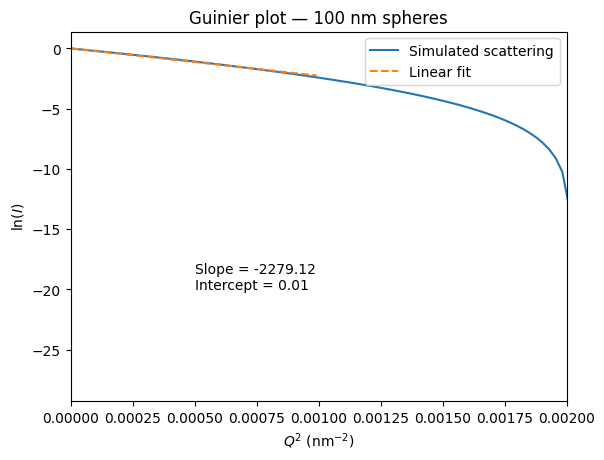

In [6]:
# Linear fit in the Guinier regime (Q² < 0.001 nm⁻²)
cut_ind  = np.where(q2 < 0.001)
cut_q2   = q2[cut_ind]
cut_lnI  = lnI[cut_ind]

slope, intercept, r_value, p_value, std_err = linregress(cut_q2, cut_lnI)

fig, ax = plt.subplots()
ax.plot(q2, lnI, label='Simulated scattering')
ax.plot(cut_q2, slope * cut_q2 + intercept, label='Linear fit', linestyle='--')
ax.set_xlabel(r'$Q^2\ (\mathrm{nm}^{-2})$')
ax.set_ylabel(r'$\ln(I)$')
ax.set_title('Guinier plot — 100 nm spheres')
ax.set_xlim(0, 0.002)
ax.legend()
ax.text(0.0005, -20, f'Slope = {slope:.2f}\nIntercept = {intercept:.2f}')

In [7]:
# Extract radius from Guinier slope
R_guinier = (-slope * 5)**0.5
print(f'Input radius:          100.0 nm')
print(f'Guinier-extracted R:   {R_guinier:.2f} nm')
print()
print('The small discrepancy comes from the choice of Q² cutoff.')
print('The fit is only truly linear in the limit Q → 0.')

Input radius:          100.0 nm
Guinier-extracted R:   106.75 nm

The small discrepancy comes from the choice of Q² cutoff.
The fit is only truly linear in the limit Q → 0.


## 1.4 Bidisperse scattering

The intensity from a **bidisperse** solution (two sphere populations) is a weighted sum:

$$I(Q) = x_1 \, P(Q, r_1) + (1 - x_1) \, P(Q, r_2)$$

where $x_1$ is the number fraction of spheres with radius $r_1$.

The plot below shows how $x_1$ affects the scattering for $r_1 = 30$ nm and $r_2 = 40$ nm.

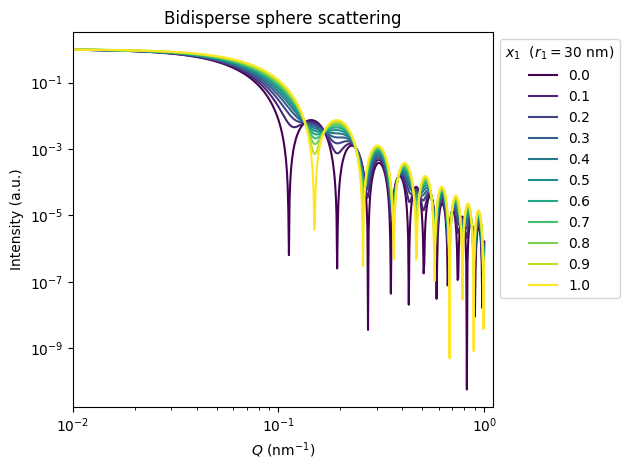

In [8]:
r1, r2 = 30., 40.
proportions = np.linspace(0., 1., 11)
pcol = iter(cm.viridis(np.linspace(0, 1, len(proportions))))

fig, ax = plt.subplots()
for p in proportions:
    scatter_bi = FQ2_sphere(r1, qrange) * p + FQ2_sphere(r2, qrange) * (1 - p)
    ax.plot(qrange, scatter_bi, color=next(pcol), label=f'{round(p, 1)}')

ax.set_xlabel(r'$Q\ (\mathrm{nm}^{-1})$')
ax.set_ylabel('Intensity (a.u.)')
ax.set_title('Bidisperse sphere scattering')
ax.legend(title=r'$x_1$  ($r_1 = 30$ nm)', bbox_to_anchor=(1, 1))
ax.loglog()
ax.set_xlim(0.01, 1.1)
plt.tight_layout()

## 1.5 Load the unknown distribution

Below we load the target scattering data. Your goal is to find $r_1$, $r_2$, and $x_1$ that best reproduce it.

Text(0.5, 1.0, 'Unknown distribution — target data')

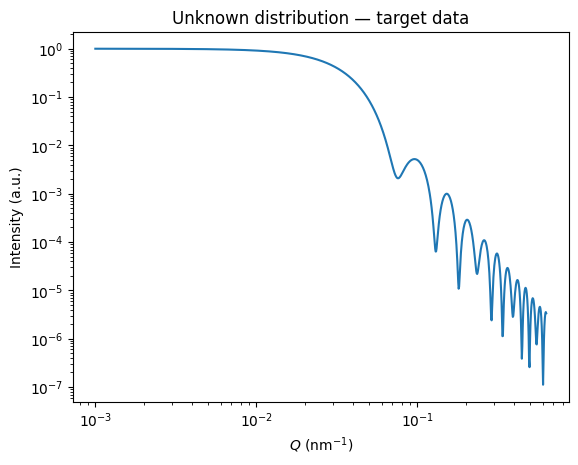

In [9]:
target = pd.read_csv('MSE7530/sampledata/unknown_distribution.csv')

fig, ax = plt.subplots()
ax.plot(target['q (nm-1)'], target['I'])
ax.loglog()
ax.set_xlabel(r'$Q\ (\mathrm{nm}^{-1})$')
ax.set_ylabel('Intensity (a.u.)')
ax.set_title('Unknown distribution — target data')

In [10]:
# Convert to log₁₀ intensity and numpy arrays for fitting
# Using log₁₀(I) gives more equal weight to features at low and high Q
log_uk_scatter = np.asarray(np.log10(target['I']))
q_uk           = np.asarray(target['q (nm-1)'])

## 1.6 Example: RSS for a single parameter set

The **residual sum of squares (RSS)** measures how well a simulated curve matches the data:

$$\text{RSS} = \sqrt{\sum_i \left[\log_{10}(I_\text{data},_i) - \log_{10}(I_\text{sim},_i)\right]^2}$$

Here is the RSS for one example pair ($r_1 = 30$ nm, $r_2 = 40$ nm, $x_1 = 0.5$).

RSS = 27.3204


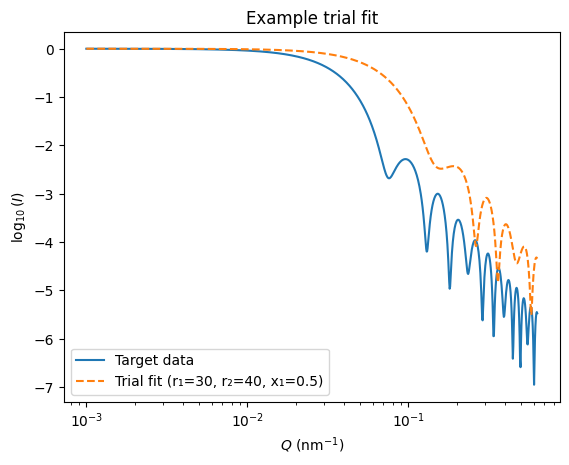

In [11]:
r1, r2, p = 30., 40., 0.5
sim_scatter     = FQ2_sphere(r1, q_uk) * p + FQ2_sphere(r2, q_uk) * (1 - p)
log_sim_scatter = np.log10(sim_scatter)
RSS             = np.sqrt(np.sum((log_uk_scatter - log_sim_scatter)**2))

fig, ax = plt.subplots()
ax.plot(q_uk, log_uk_scatter,     label='Target data')
ax.plot(q_uk, log_sim_scatter, '--', label=f'Trial fit (r₁=30, r₂=40, x₁=0.5)')
ax.set_xlabel(r'$Q\ (\mathrm{nm}^{-1})$')
ax.set_ylabel(r'$\log_{{10}}(I)$')
ax.set_title('Example trial fit')
ax.semilogx()
ax.legend()
print(f'RSS = {RSS:.4f}')

## 1.7 Scanning over one radius pair

Here we show that scanning $x_1$ for a fixed $(r_1, r_2)$ finds a minimum RSS — but we need to search all radius combinations too.

In [12]:
test_props = np.linspace(0., 1., 11)
test_r     = np.linspace(10., 200., 20)
print(f'Grid size: {len(test_props)} × {len(test_r)} × {len(test_r)} = '
      f'{len(test_props) * len(test_r)**2} parameter sets')

Grid size: 11 × 20 × 20 = 4400 parameter sets


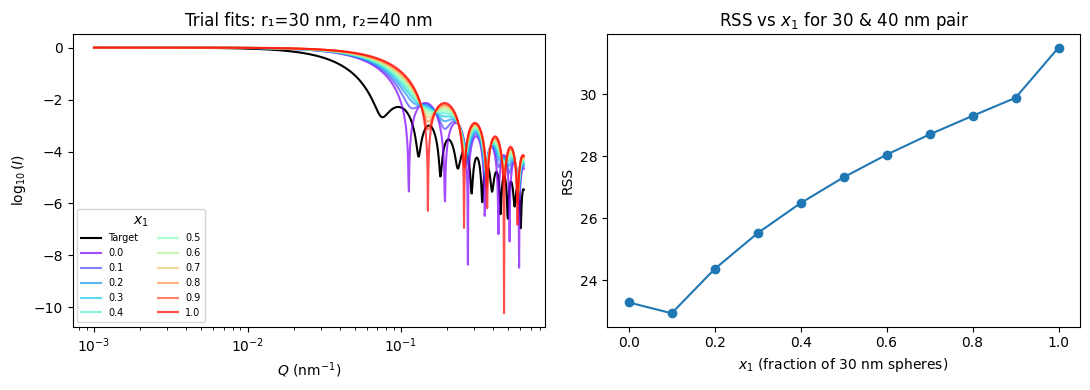

In [13]:
# Example: scan x₁ for r₁=30 nm, r₂=40 nm
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
pcol = iter(cm.rainbow(np.linspace(0, 1, len(test_props))))
rsums = np.zeros(len(test_props))
r1, r2 = 30., 40.

axes[0].plot(q_uk, log_uk_scatter, 'k', label='Target', linewidth=1.5)
for i, p in enumerate(test_props):
    sim  = FQ2_sphere(r1, q_uk) * p + FQ2_sphere(r2, q_uk) * (1 - p)
    lsim = np.log10(sim)
    rsums[i] = np.sqrt(np.sum((log_uk_scatter - lsim)**2))
    axes[0].plot(q_uk, lsim, color=next(pcol), label=f'{round(p,1)}', alpha=0.7)

axes[0].semilogx()
axes[0].set_xlabel(r'$Q\ (\mathrm{nm}^{-1})$')
axes[0].set_ylabel(r'$\log_{{10}}(I)$')
axes[0].legend(title='$x_1$', fontsize=7, ncol=2)
axes[0].set_title('Trial fits: r₁=30 nm, r₂=40 nm')

axes[1].plot(test_props, rsums, 'o-')
axes[1].set_xlabel('$x_1$ (fraction of 30 nm spheres)')
axes[1].set_ylabel('RSS')
axes[1].set_title('RSS vs $x_1$ for 30 & 40 nm pair')
plt.tight_layout()

---
## ✏️ ANSWER - PART 1

**Find the values of $r_1$, $r_2$, and $x_1$ that give the best fit to the unknown distribution.**

You have already seen how to compute RSS for one parameter set and scan over $x_1$ for a fixed radius pair. Now extend this to search the full 3-D parameter grid (`test_r` × `test_r` × `test_props`).

**Deliverables:**
1. Code that searches the parameter grid and records the RSS for every combination.
2. The best-fit values of $r_1$, $r_2$, and $x_1$.
3. A plot comparing your best-fit simulated curve to the target data.

**Bonus / exam connection:** Once you have your answer, go back to the lecture slides on optimization and identify how each variable in your code connects to the formal mathematical definitions of least-squares fitting.

> *Hint: you can store results in a 3-D numpy array (`rss_grid[i, j, k]`) indexed by `(r1_idx, r2_idx, prop_idx)` and use `np.argmin` to find the minimum.*

In [18]:
# Your code here
log_uk_scatter = np.asarray(np.log10(target['I'])) # taking the log for better fit meaning
q_uk = np.asarray(target['q (nm-1)'])

# coarse search
test_props = np.linspace(0., 1., 11)
test_r = np.linspace(10., 200., 20)
print(f'This results in {len(test_props)*len(test_r)*len(test_r)} parameter sets to test')

This results in 4400 parameter sets to test


In [19]:
# Your code here
min_RSS_update = float('inf')
opt_r1 = 0.0
opt_r2 = 0.0
opt_t = 0.0

for t in test_props:
  for r1 in test_r:
    for r2 in test_r:
      sim_scatter = FQ2_sphere(r1, q_uk)*t + FQ2_sphere(r2, q_uk)*(1-t)
      log_sim_scatter = np.log10(sim_scatter)
      RSS = (np.sum((log_uk_scatter - log_sim_scatter)**2))**0.5
      if RSS < min_RSS_update:
        print(f'optimal RSS updated to {RSS}, with r1 = {r1}, r2 = {r2}, and p = {t}')
        min_RSS_update = RSS

        opt_r1 = r1
        opt_r2 = r2
        opt_t = t

optimal RSS updated to 60.0102094405897, with r1 = 10.0, r2 = 10.0, and p = 0.0
optimal RSS updated to 42.479505109903165, with r1 = 10.0, r2 = 20.0, and p = 0.0
optimal RSS updated to 31.509815970747997, with r1 = 10.0, r2 = 30.0, and p = 0.0
optimal RSS updated to 23.27794918658252, with r1 = 10.0, r2 = 40.0, and p = 0.0
optimal RSS updated to 20.04432840504073, with r1 = 10.0, r2 = 50.0, and p = 0.0
optimal RSS updated to 9.898053441921459, with r1 = 10.0, r2 = 60.0, and p = 0.0
optimal RSS updated to 8.279614679648333, with r1 = 40.0, r2 = 60.0, and p = 0.1
optimal RSS updated to 5.357820479674509, with r1 = 50.0, r2 = 60.0, and p = 0.1
optimal RSS updated to 3.7799943622354713, with r1 = 70.0, r2 = 60.0, and p = 0.1
optimal RSS updated to 3.0600875264084957, with r1 = 80.0, r2 = 60.0, and p = 0.1
optimal RSS updated to 1.3323141431865626, with r1 = 80.0, r2 = 60.0, and p = 0.2
optimal RSS updated to 1.1384824819241975e-12, with r1 = 80.0, r2 = 60.0, and p = 0.30000000000000004


[]

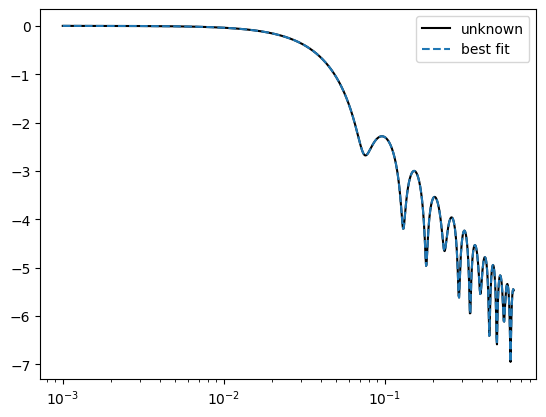

In [20]:
# Your code here
fig, ax = plt.subplots()
pcol = iter(cm.rainbow(np.linspace(0,1,len(proportions))))
ax.plot(q_uk, log_uk_scatter,label='unknown',color='k')
best_sim_scatter = FQ2_sphere(opt_r1, q_uk)*opt_t + FQ2_sphere(opt_r2, q_uk)*(1-opt_t)
log_best_sim_scatter = np.log10(best_sim_scatter)
ax.plot(q_uk, log_best_sim_scatter, '--',label='best fit')
ax.legend()
ax.semilogx()

---
# Part 2: Guinier Fitting of Protein $R_g$

For the **ABC transporter ATP-binding protein** ([SASDW27](https://www.sasbdb.org/data/SASDW27/)), determine $R_g$ by Guinier analysis.

For any sufficiently dilute particle — regardless of shape — the Guinier approximation gives:

$$I(Q) \approx \Delta\rho^2 V_p^2 \, e^{-Q^2 R_g^2/3}$$

Therefore a plot of $\ln I$ vs $Q^2$ is linear at low $Q$, with slope $= -R_g^2/3$, so:

$$R_g = \sqrt{-3 \times \text{slope}}$$

The data are loaded below.

In [21]:
# Load SAXS data for the ABC transporter protein
# (unusual format — column renaming required)
ABC_data = pd.read_csv('MSE7530/sampledata/HW4/SASDW27.dat', sep=' ', header=3)
ABC_data = ABC_data.rename(columns={
    ABC_data.columns[1]: 'q',
    ABC_data.columns[3]: 'I',
    ABC_data.columns[5]: 'sigma',
})
ABC_data = ABC_data.drop(['Unnamed: 0', 'Unnamed: 2', 'Unnamed: 4', 'sigma'], axis=1)
ABC_data.head(10)

,q,I
0,0.088611,134.7205
1,0.093763,136.1162
2,0.098915,134.7574
3,0.104067,133.7519
4,0.109219,129.0652
5,0.114371,126.7226
6,0.119523,127.7186
7,0.124675,124.5161
8,0.129827,121.7891
9,0.134979,120.7219


[]

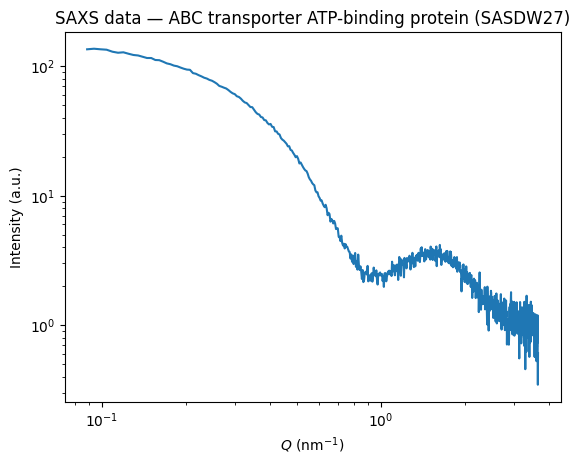

In [22]:
# Preview the full dataset
fig, ax = plt.subplots()
ax.plot(ABC_data['q'], ABC_data['I'])
ax.set_xlabel(r'$Q\ (\mathrm{nm}^{-1})$')
ax.set_ylabel('Intensity (a.u.)')
ax.set_title('SAXS data — ABC transporter ATP-binding protein (SASDW27)')
ax.loglog()

---
## ✏️ Your Task — Part 2

**Find the $R_g$ of the ABC transporter protein using a Guinier plot.**

Follow the same approach demonstrated in Section 1.3:
1. Construct a Guinier plot ($\ln I$ vs $Q^2$).
2. Identify a suitable linear region at low $Q$ (consider $QR_g < 1.3$ as a rough guide for the upper limit).
3. Fit a line to that region and extract $R_g$ from the slope.
4. Show your Guinier plot with the linear fit overlaid.

> *Think about: how sensitive is your answer to the choice of $Q$ cutoff? What does that tell you about the reliability of the Guinier approximation?*

(4.0, 5.0)

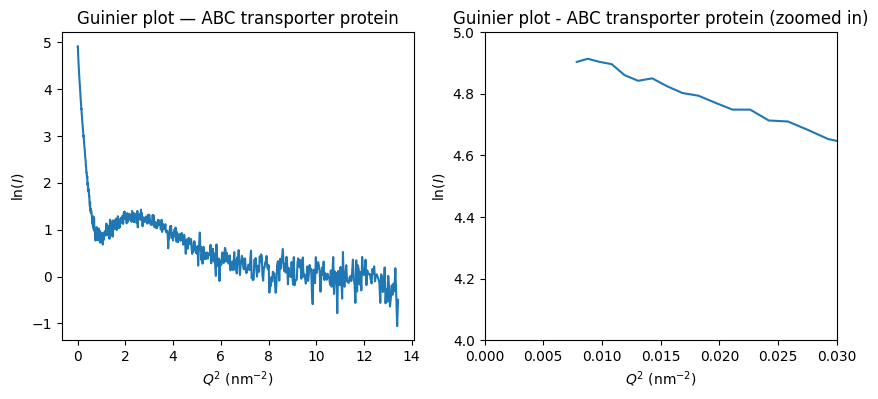

In [34]:
# Your code here
fig, ax = plt.subplots(1,2,figsize=(10,4))
for a in ax:
  a.plot(ABC_data['q']**2, np.log(ABC_data['I']))
  a.set_xlabel(r'$Q^2\ (\mathrm{nm}^{-2})$')
  a.set_ylabel(r'$\ln(I)$')
ax[0].set_title('Guinier plot — ABC transporter protein')
ax[1].set_title('Guinier plot - ABC transporter protein (zoomed in)')
ax[1].set_xlim(0,.03);ax[1].set_ylim(4,5)

In [43]:
# Your code here
q2 = np.asarray(ABC_data['q']**2)
lnI = np.asarray(np.log(ABC_data['I']))
cut_ind = np.where(q2 < 0.03) # returns the indices of where q2 is less than 0.03
cut_q2 = q2[cut_ind]
cut_lnI = lnI[cut_ind]
print(f'This leaves us with {len(cut_q2)} points (just for your information)')

This leaves us with 17 points (just for your information)


Text(0.5, 1.0, 'Guinier plot - ABC transporter protein (zoomed in)')

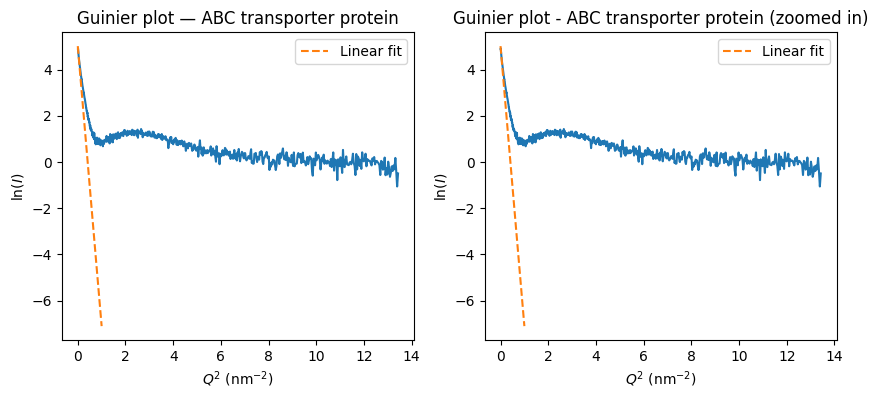

In [47]:
# Your code here
slope, intercept, r_value, p_value, std_err = linregress(cut_q2, cut_lnI)
test_q2 = np.linspace(0.,1., 100) # this is just so that we can visualize the guinier slope past the small bit
fig, ax = plt.subplots(1,2,figsize=(10,4))
for a in ax:
  a.plot(ABC_data['q']**2, np.log(ABC_data['I']))
  a.set_xlabel(r'$Q^2\ (\mathrm{nm}^{-2})$')
  a.set_ylabel(r'$\ln(I)$')
  a.plot(test_q2, slope * test_q2 + intercept, label='Linear fit', linestyle='--')
  a.legend()
ax[0].set_title('Guinier plot — ABC transporter protein')
ax[1].set_title('Guinier plot - ABC transporter protein (zoomed in)')
#ax[1].set_xlim(0,.03);ax[1].set_ylim(4,5)

In [50]:
print(f'The radius extracted from the Guinier plot is {(-slope*3)**0.5} nm')

The radius extracted from the Guinier plot is 6.027686105080997 nm


In [56]:
f'The value of Q at which Q*R_g = 1.3 is {(1.3/6.)}, or {(1.3/6.)**2} in Q^2, so you should fit no higher than that. We used 0.03 as the maximum limit, so we are fine'

'The value of Q at which Q*R_g = 1.3 is 0.21666666666666667, or 0.04694444444444445 in Q^2, so you should fit no higher than that. We used 0.03 as the maximum limit, so we are fine'

Bonus: testing calculated Rg as a function of changing cutoff

In [59]:
q2[0] # the minimum value of q2 in our data

np.float64(0.0078518419767844)

/tmp/ipykernel_2176/1195343547.py:8: RuntimeWarning: invalid value encountered in scalar power
  calc_Rgs[i] = (-slope*3)**0.5


Text(0.05, 5.0, 'Rule-of-thumb cutoff')

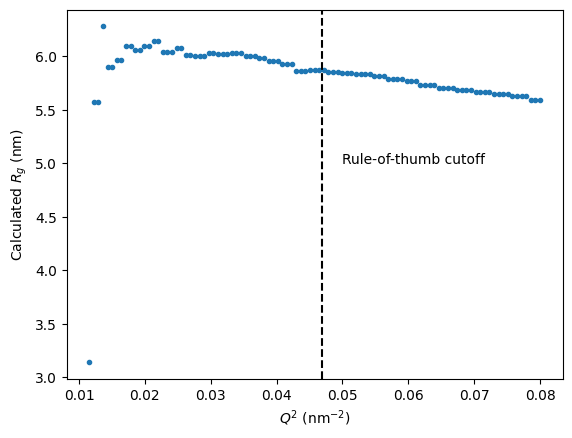

In [70]:
test_cutoffs = np.linspace(q2[3], 0.08,100) # generates a list of cutoff q2 values that will yield at least 3 points, up to higher than we should be going for a Guiner limit (0.08, when max should be 0.0469)
calc_Rgs = np.zeros(len(test_cutoffs))
for i, cutoff in enumerate(test_cutoffs):
  cut_ind = np.where(q2 < cutoff)
  cut_q2 = q2[cut_ind]
  cut_lnI = lnI[cut_ind]
  slope, intercept, r_value, p_value, std_err = linregress(cut_q2, cut_lnI)
  calc_Rgs[i] = (-slope*3)**0.5

fig, ax = plt.subplots()
ax.plot(test_cutoffs, calc_Rgs,'o',markersize=3)
ax.set_xlabel(r'$Q^2\ (\mathrm{nm}^{-2})$')
ax.set_ylabel(r'Calculated $R_g\ (\mathrm{nm})$')
ax.axvline(0.0469,color='k',linestyle='--')
ax.text(0.05, 5.0, 'Rule-of-thumb cutoff')


At extremely low cutoffs, we just didn't have enough data points for a statistically meaningful fit. We can see the value slowly start to decline as we fit more points.